# Parte A: Series de Fourier

## Objetivo
Representar funciones periodicas mediante una serie de fourier truncada y evaluar su aproximacion usando la integral cuadrada del error (ICE).

## Primera Funcion
la funcion f1(t) vale 1 cuando -1 < t < 1 y vale 0 en el resto del intervalo de -2 a 2

In [5]:
import numpy as np

T = 4
t = np.linspace(-2, 2, 9)

print(t)

[-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]


In [6]:
f1 = np.where((t > -1) & (t < 1), 1, 0)

print(f1)

[0 0 0 1 1 1 0 0 0]


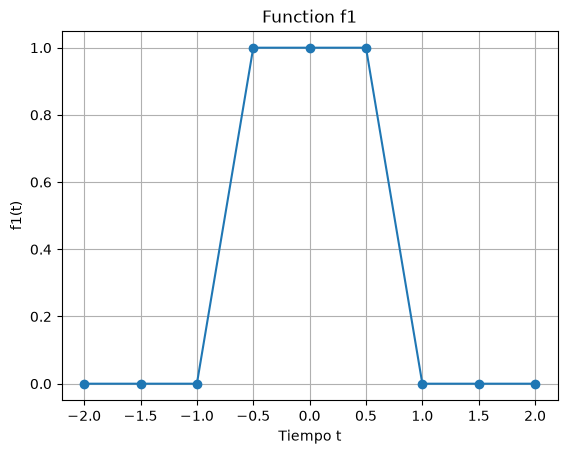

In [7]:
import matplotlib.pyplot as plt

plt.plot(t, f1, marker='o')
plt.xlabel('Tiempo t')
plt.ylabel('f1(t)')
plt.title('Function f1')
plt.grid(True)
plt.show()

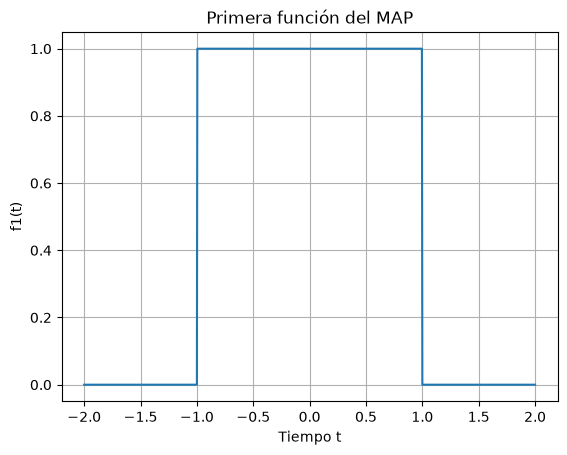

In [8]:
t = np.linspace(-2, 2, 1001)
f1 = np.where((t > -1) & (t < 1), 1, 0)

plt.plot(t, f1)
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función del MAP")
plt.grid(True)
plt.show()

In [9]:
def funcion_1(t):
    return np.where((t > -1) & (t < 1), 1, 0)

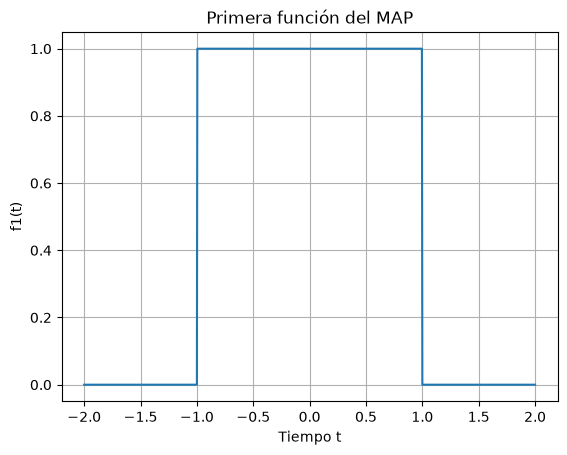

In [10]:
valores = funcion_1(t)

plt.plot(t, valores)
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función del MAP")
plt.grid(True)
plt.show()

In [11]:
def funcion_2(t):
    return np.where((t > -1) & (t < 1), t + 2, 0)

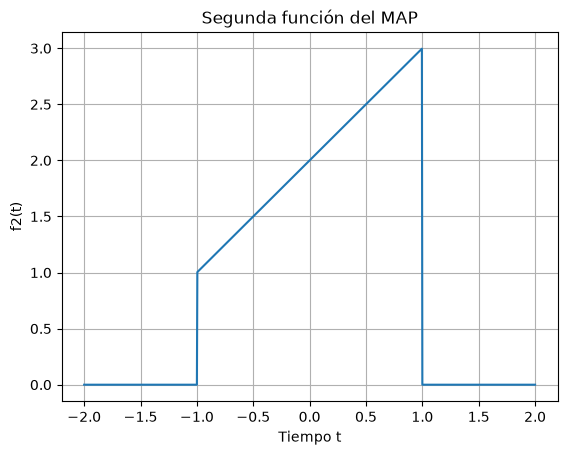

In [12]:
valores_2 = funcion_2(t)

plt.plot(t, valores_2)
plt.xlabel("Tiempo t")
plt.ylabel("f2(t)")
plt.title("Segunda función del MAP")
plt.grid(True)
plt.show()

In [13]:
def tiempo_periodico(t):
    return (t + 2) % 4 - 2

In [14]:
tiempos_prueba = np.array([0, 4, 8, -4, 4.5])

print(tiempo_periodico(tiempos_prueba))

[0.  0.  0.  0.  0.5]


In [15]:
def funcion_1_periodica(t):
    return funcion_1(tiempo_periodico(t))

def funcion_2_periodica(t):
    return funcion_2(tiempo_periodico(t))

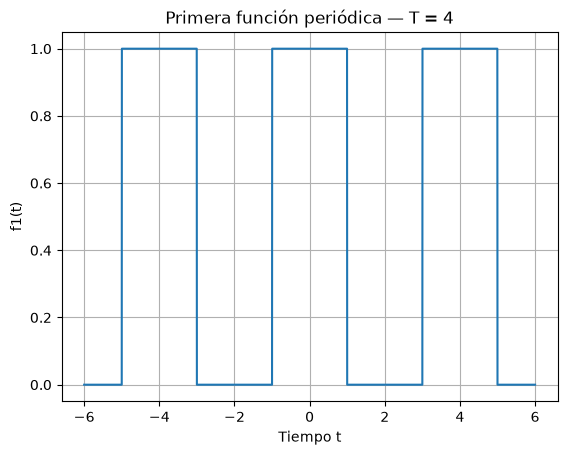

In [16]:
t_amplio = np.linspace(-6, 6, 3001)

plt.plot(t_amplio, funcion_1_periodica(t_amplio))
plt.xlabel("Tiempo t")
plt.ylabel("f1(t)")
plt.title("Primera función periódica — T = 4")
plt.grid(True)
plt.show()

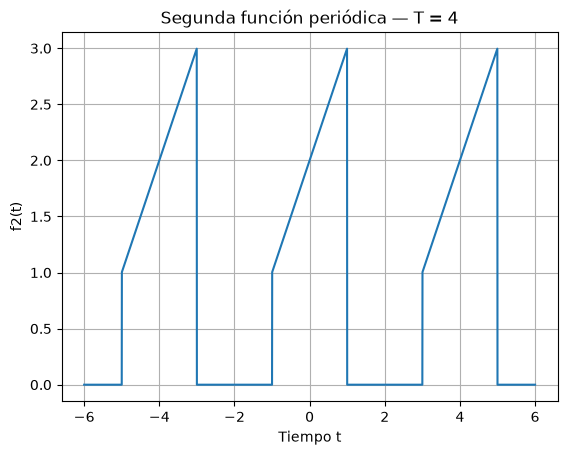

In [17]:
plt.plot(t_amplio, funcion_2_periodica(t_amplio))
plt.xlabel("Tiempo t")
plt.ylabel("f2(t)")
plt.title("Segunda función periódica — T = 4")
plt.grid(True)
plt.show()

In [18]:
omega_0 = 2 * np.pi / T

print("Período:", T)
print("Frecuencia angular fundamental:", omega_0)

Período: 4
Frecuencia angular fundamental: 1.5707963267948966


In [19]:
a0_f1 = 2 / T
a0_f2 = 4 / T

print("Valor promedio de f1:", a0_f1)
print("Valor promedio de f2:", a0_f2)

Valor promedio de f1: 0.5
Valor promedio de f2: 1.0


## Interfaz Para la parte A:

Aqui se desarolla una interfaz interactiva para que el usuario tenga la opcion de visualizar cualquiera de las dos funciones (f1 o f2)
Por lo que tendra un menu en donde pueda seleccionar
- Menu para elegir su funcion
- Control para mostrar entre 1 y 5 periodos
- Grafica que se actualiza al cambiar los controles
- Periodo y frecuencia angular
- Opcion para activar o quitar la cuadricula

### Instalacion de ipywidgets
la biblioteca ipywidgets permite crear controles interactivo dentro del notebook, como menus desplegables, deslizadores y casillas.

si no esta instala, ejecutar el siguiente comando en una celda de codigo: 

--------------------------------
```python
%pip install ipywidgets
```
--------------------------------

%pip ejecuta el instalador de paquetes en el entorno de Python asociado al kernel actual del notebook.

Despues de instalar la biblioteca, reiniciar el kernel y volver a ejecutar la celda de la interfaz. La instalacion normalmente solo se necesita una vez por entorno.

In [3]:
# 1. BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


# 2. PERÍODO Y FUNCIONES
T = 4
omega_0 = 2 * np.pi / T


def funcion_1(t):
    return np.where((t > -1) & (t < 1), 1, 0)


def funcion_2(t):
    return np.where((t > -1) & (t < 1), t + 2, 0)


def tiempo_periodico(t):
    t = np.asarray(t)
    return (t + T / 2) % T - T / 2


def funcion_1_periodica(t):
    return funcion_1(tiempo_periodico(t))


def funcion_2_periodica(t):
    return funcion_2(tiempo_periodico(t))


# 3. ENCABEZADO Y CONTROLES

encabezado = widgets.HTML("""
<div style="
    background: linear-gradient(120deg, #172554, #4338ca);
    padding: 28px;
    border-radius: 16px;
    color: white;
    font-family: sans-serif;
    margin-bottom: 18px;
">
    <div style="
        color: #a5b4fc;
        font-size: 12px;
        font-weight: bold;
        letter-spacing: 2px;
    ">
        MATEMÁTICA APLICADA · PARTE A
    </div>

    <h1 style="color: white; margin: 12px 0; font-size: 28px;">
        Bienvenido a MAP Series de Fourier
    </h1>

    <p style="color: #e0e7ff; font-size: 15px; margin: 0;">
        Explora nuestras señales periódicas.
        ¿Qué función deseas visualizar?
    </p>
</div>
""")

selector_funcion = widgets.Dropdown(
    options=[
        ("f1 · Pulso rectangular", "f1"),
        ("f2 · Rampa por tramos", "f2")
    ],
    value="f1",
    description="Función:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="330px", max_width="100%")
)

selector_periodos = widgets.IntSlider(
    value=3,
    min=1,
    max=5,
    step=1,
    description="Períodos:",
    continuous_update=False,
    style={
        "description_width": "80px",
        "handle_color": "#6366f1"
    },
    layout=widgets.Layout(width="330px", max_width="100%")
)

control_cuadricula = widgets.Checkbox(
    value=True,
    description="Mostrar cuadrícula",
    indent=False,
    layout=widgets.Layout(margin="8px 0 0 12px")
)

panel_controles = widgets.VBox(
    [
        widgets.HTML("""
        <div style="
            color: #312e81;
            font-family: sans-serif;
            margin: 0 0 12px 8px;
        ">
            <b>01 · Configura tu visualización</b>
            <p style="color: #475569; margin: 6px 0;">
                Elige una señal y ajusta cuántos períodos quieres ver.
            </p>
        </div>
        """),
        selector_funcion,
        selector_periodos,
        control_cuadricula
    ],
    layout=widgets.Layout(
        padding="18px",
        border="1px solid #c7d2fe",
        margin="0 0 18px 0",
        width="100%"
    )
)

# Estas tarjetas se actualizarán al cambiar los controles.
tarjetas = widgets.HTML()


# 4. ACTUALIZACIÓN DE RESULTADOS

def actualizar_grafica(nombre, periodos, cuadricula):
    if nombre == "f1":
        funcion = funcion_1_periodica
        titulo = "Pulso rectangular"
        color = "#6366f1"
        descripcion = (
            "Un pulso de amplitud 1 entre −1 y 1, "
            "que se repite cada 4 unidades de tiempo."
        )
    else:
        funcion = funcion_2_periodica
        titulo = "Rampa por tramos"
        color = "#0d9488"
        descripcion = (
            "Una rampa definida por t + 2 entre −1 y 1, "
            "que se repite cada 4 unidades de tiempo."
        )

    # Tarjetas informativas con HTML.
    tarjetas.value = f"""
    <div style="
        display: flex;
        flex-wrap: wrap;
        gap: 12px;
        font-family: sans-serif;
        margin-bottom: 20px;
    ">
        <div style="
            flex: 1; min-width: 170px; padding: 18px;
            background: #eef2ff; border-radius: 12px;
            border: 1px solid #c7d2fe;
        ">
            <div style="color: #475569; font-size: 12px;">
                SEÑAL SELECCIONADA
            </div>
            <div style="
                color: #3730a3; font-size: 20px;
                font-weight: bold; margin-top: 8px;
            ">
                {nombre} · {titulo}
            </div>
        </div>

        <div style="
            flex: 1; min-width: 140px; padding: 18px;
            background: #f0fdfa; border-radius: 12px;
            border: 1px solid #99f6e4;
        ">
            <div style="color: #475569; font-size: 12px;">
                PERÍODO FUNDAMENTAL
            </div>
            <div style="
                color: #0f766e; font-size: 24px;
                font-weight: bold; margin-top: 8px;
            ">
                T = {T}
            </div>
        </div>

        <div style="
            flex: 1; min-width: 140px; padding: 18px;
            background: #fff7ed; border-radius: 12px;
            border: 1px solid #fed7aa;
        ">
            <div style="color: #475569; font-size: 12px;">
                FRECUENCIA ANGULAR
            </div>
            <div style="
                color: #c2410c; font-size: 24px;
                font-weight: bold; margin-top: 8px;
            ">
                ω₀ = {omega_0:.4f}
            </div>
            <div style="color: #9a3412; font-size: 12px;">
                rad/unidad de tiempo
            </div>
        </div>
    </div>

    <div style="font-family: sans-serif; margin-bottom: 8px;">
        <b style="color: #312e81;">02 · Explora la señal</b>
        <p style="color: #475569;">{descripcion}</p>
    </div>
    """

    limite = periodos * T / 2
    tiempos = np.linspace(
        -limite,
        limite,
        periodos * 1000 + 1
    )
    valores = funcion(tiempos)

    # Estilo local: no cambia las gráficas anteriores del notebook.
    with plt.style.context("default"):
        fig, ax = plt.subplots(figsize=(9, 3.8))
        fig.patch.set_facecolor("#ffffff")
        ax.set_facecolor("#f8fafc")

        ax.plot(
            tiempos,
            valores,
            color=color,
            linewidth=2.4,
            label=f"{nombre}(t)"
        )

        ax.fill_between(
            tiempos,
            valores,
            0,
            color=color,
            alpha=0.10
        )

        ax.set_title(
            f"{titulo} · {periodos} período(s)",
            loc="left",
            fontsize=14,
            fontweight="bold",
            color="#1e293b",
            pad=18
        )

        ax.set_xlabel("Tiempo t", color="#475569")
        ax.set_ylabel("Amplitud", color="#475569")
        ax.tick_params(colors="#475569")

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#cbd5e1")
        ax.spines["bottom"].set_color("#cbd5e1")

        if cuadricula:
            ax.grid(True, color="#cbd5e1", alpha=0.5)
        else:
            ax.grid(False)

        ax.set_axisbelow(True)
        ax.legend(
            loc="upper right",
            frameon=True,
            facecolor="white",
            edgecolor="#e2e8f0",
            labelcolor="#334155"
        )

        fig.tight_layout()
        plt.show()
        plt.close(fig)


# 5. CONEXIÓN DE LOS CONTROLES

salida = widgets.interactive_output(
    actualizar_grafica,
    {
        "nombre": selector_funcion,
        "periodos": selector_periodos,
        "cuadricula": control_cuadricula
    }
)

salida.layout = widgets.Layout(
    width="100%",
    overflow="auto"
)


# 6. PRESENTACIÓN FINAL

pie = widgets.HTML("""
<div style="
    font-family: sans-serif;
    color: #64748b;
    font-size: 12px;
    padding: 14px 0 4px 0;
">
    Visualización de las señales originales ·
    Los controles actualizan la gráfica automáticamente.
</div>
""")

interfaz = widgets.VBox(
    [
        encabezado,
        panel_controles,
        tarjetas,
        salida,
        pie
    ],
    layout=widgets.Layout(
        width="100%",
        max_width="1050px",
        padding="20px",
        border="1px solid #e2e8f0"
    )
)

display(interfaz)

In [1]:
print("Iniciando importaciones...")

import numpy as np
print("NumPy listo")

import matplotlib.pyplot as plt
print("Matplotlib listo")

import ipywidgets as widgets
print("ipywidgets listo")

from IPython.display import display
print("Todo listo")

Iniciando importaciones...
NumPy listo
Matplotlib listo
ipywidgets listo
Todo listo
